# Role Intelligence
Analyzing attrition and performance by Department and Job Role from real data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/employee_attrition_processed.csv')
print(f'Departments: {df["Department"].nunique()}')
print(df['Department'].value_counts())
print()
print(f'Job Roles: {df["JobRole"].nunique()}')
print(df['JobRole'].value_counts())

Departments: 6
Department
Sales        99
IT           93
Support      82
Finance      77
HR           77
Marketing    72
Name: count, dtype: int64

Job Roles: 13
JobRole
Account Manager     50
Sales Executive     49
Helpdesk            42
Support Engineer    40
HR Executive        39
Accountant          39
Auditor             38
HR Manager          38
Developer           38
Content Lead        38
SEO Analyst         34
Tester              30
Engineer            25
Name: count, dtype: int64


Attrition Rate by Department:
            sum  count  AttritionRate
Department                           
IT           16     93           17.2
Finance      11     77           14.3
Sales        11     99           11.1
HR            8     77           10.4
Support       6     82            7.3
Marketing     3     72            4.2


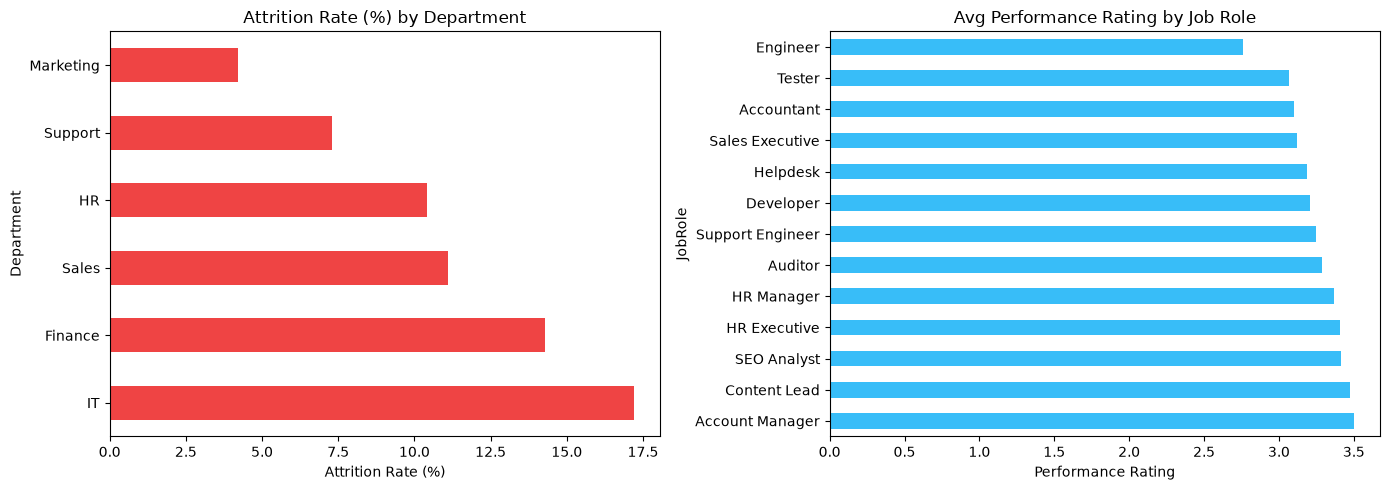

Role master saved.


In [2]:
# Attrition rate by department
dept_risk = df.groupby('Department')['Attrition_encoded'].agg(['sum', 'count'])
dept_risk['AttritionRate'] = (dept_risk['sum'] / dept_risk['count'] * 100).round(1)
dept_risk = dept_risk.sort_values('AttritionRate', ascending=False)
print('Attrition Rate by Department:')
print(dept_risk.to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
dept_risk['AttritionRate'].plot(kind='barh', ax=ax1, color='#ef4444')
ax1.set_title('Attrition Rate (%) by Department')
ax1.set_xlabel('Attrition Rate (%)')

if 'PerformanceRating' in df.columns:
    role_perf = df.groupby('JobRole')['PerformanceRating'].mean().sort_values(ascending=False)
    role_perf.plot(kind='barh', ax=ax2, color='#38bdf8')
    ax2.set_title('Avg Performance Rating by Job Role')
    ax2.set_xlabel('Performance Rating')

plt.tight_layout()
plt.savefig('../data/processed/role_intelligence.png', dpi=100, bbox_inches='tight')
plt.show()

# Save role master table
role_master = df[['JobRole', 'Department']].drop_duplicates().reset_index(drop=True)
role_master.to_csv('../data/processed/role_master.csv', index=False)
print('Role master saved.')